# Vielteilchenlokalisierung

Das Notebook gibt der Mixed-Field-Ising-Kette zufällige Längsfelder der Stärke $W$ und verfolgt mit exakter Diagonalisierung (bis 12 Qubits, über viele Realisierungen gemittelt) den Übergang vom chaotischen zum vielteilchenlokalisierten Verhalten: Abstandsstatistik, Verschränkung und Erwartungswerte der Eigenzustände, das Gedächtnis an den Anfangszustand und das logarithmisch langsame Wachstum der Verschränkung nach einem Quench bis $t = 10^6$.

Kann ein wechselwirkendes Quantensystem mit genug Unordnung für immer ein Gedächtnis an seinen Anfangszustand behalten, und woran erkennt man das im Spektrum, in den Eigenzuständen und in der Dynamik?

#### **Hintergrund**

Anderson zeigte 1958, dass ein einzelnes Elektron in einem ungeordneten Kristall gefangen bleiben kann: Die Streuung an den Störstellen löscht die Welle in alle Richtungen aus, die Wellenfunktionen fallen exponentiell ab, und es fließt kein Strom (**Anderson-Lokalisierung**). In einer Dimension genügt dafür jede noch so schwache Unordnung. Lange blieb offen, ob das auch für viele wechselwirkende Teilchen bei endlicher Energie gilt, denn Wechselwirkungen erlauben, Energie zwischen den Teilchen zu tauschen, und sollten das System thermalisieren. Basko, Aleiner und Altshuler (2006) sowie Gornyi, Mirlin und Polyakov (2005) argumentierten, dass die Lokalisierung überleben kann; Oganesyan und Huse (2007) und Pal und Huse (2010) fanden die **Vielteilchenlokalisierung** (MBL, many-body localization) numerisch in Spinketten, und Imbrie (2016) bewies sie für eine Ising-Kette mit zufälligen Feldern, fast dasselbe Modell wie hier, unter einer Annahme über die Abstoßung der Niveaus.

Ein vielteilchenlokalisiertes System verletzt die Eigenzustands-Thermalisierung ([Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb)): Es thermalisiert nie, obwohl es wechselwirkt, und behält lokale Information über seinen Anfangszustand für beliebig lange Zeiten. Schreiber et al. (2015) haben das mit kalten Atomen in einem quasizufälligen optischen Gitter gemessen, Smith et al. (2016) mit zehn gefangenen Ionen, Roushan et al. (2017) mit supraleitenden Qubits. Für Quantencomputer und Quantenspeicher ist das interessant, weil ein lokalisiertes System Information schützen kann. Diskrete Zeitkristalle, angetriebene Systeme, die nicht aufheizen, beruhen ebenfalls auf Lokalisierung.

Das Notebook nimmt die Ising-Kette der ganzen Serie ($J = h_x = 1$) und ersetzt das feste Längsfeld $h_z = 0.5$ durch zufällige Felder $h_i = 0.5 + W u_i$; bei $W = 0$ ist es die chaotische Kette der anderen Notebooks.

Landkarte:

- **Statische Signaturen**
  - Spektrum (Exp. 1): Mit wachsender Unordnung fällt $\langle r\rangle$ von 0.53 (GOE) auf 0.39 (Poisson); die Kurven für 8, 10 und 12 Qubits kreuzen sich zwischen $W = 2$ und 3.
  - Eigenzustände (Exp. 2): Die Verschränkung fällt von 93 % des Page-Werts (Volumengesetz) auf fast null (Flächengesetz); $\langle Z\rangle$ in der Mitte liegt bei $W = 8$ meist nahe $\pm1$ statt bei 0.
- **Dynamik**
  - Quench aus $\vert0011\dots\rangle$ (Exp. 3): Das Gedächtnis bleibt bei $W = 4$ bei 0.48, und die Verschränkung wächst bis $t = 10^6$ wie $\log t$, um 0.22 Bit pro Zehnerpotenz der Zeit.
  - Langzeit-Gedächtnis (Exp. 4): null für schwache Unordnung, endlich für starke; auch hier kreuzen sich die Kurven zwischen $W = 2$ und 3.

Verwandte Notebooks: [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb) (die Hypothese, die hier verletzt wird), [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb), [Quantenchaos und Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb) (Page-Kurve, Lichtkegel), [Krylov-Komplexität](https://github.com/deltorobarba/science/blob/main/quantum/chaos_krylov.ipynb), [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb) (Experiment 5: eine Heisenberg-Kette mit Unordnung).

#### **Theorie**

##### *1. Anderson-Lokalisierung*

Ein Teilchen, das auf einem Gitter hüpft und an jedem Platz eine zufällige Energie sieht, hat Eigenzustände, die um einen Platz herum exponentiell abfallen, $\vert\psi(x)\vert \sim e^{-\vert x - x_0\vert/\xi}$, mit der **Lokalisierungslänge** $\xi$. Der Grund ist Interferenz: Die Wege, auf denen das Teilchen sich ausbreiten könnte, löschen sich im Mittel aus. In einer und zwei Dimensionen sind alle Zustände lokalisiert, in drei nur bei genügend starker Unordnung. Ohne Wechselwirkung kann ein solches System nicht thermalisieren: Jedes Teilchen bleibt, wo es ist.

##### *2. Das Modell*

$$H = J\sum_i Z_iZ_{i+1} + h_x\sum_i X_i + \sum_i h_iZ_i, \qquad h_i = h_z + W u_i, \quad u_i \text{ gleichverteilt in } [-1, 1] ,$$
mit $J = h_x = 1$, $h_z = 0.5$ und offenen Enden. Für jede **Realisierung** der Unordnung werden neue $u_i$ gezogen, und alle Größen werden über viele Realisierungen gemittelt. Die zufälligen Felder zerstören die Spiegelsymmetrie; es gibt keine Symmetriesektoren.
- **Kleines $W$:** die chaotische Kette der Serie, mit Wigner-Dyson-Statistik und Eigenzustands-Thermalisierung.
- **Großes $W$:** Die Felder $h_iZ_i$ sind viel größer als das Querfeld. Ein Spin umzuklappen kostet die Energie $2h_i$, die zufällig ist; das Querfeld kann nur selten zwei Konfigurationen mit fast gleicher Energie mischen (**Resonanzen**). Die Eigenzustände sind dann fast Basiszustände mit festem $Z_i$, leicht „angezogen“.

In der Sprache der Fermionen (Jordan-Wigner) ist $\sum_ih_iZ_i$ eine Wechselwirkung; das Modell ist also ein wechselwirkendes ungeordnetes System, kein Anderson-Modell.

##### *3. Lokale Erhaltungsgrößen (l-bits)*

Im vielteilchenlokalisierten Regime gibt es eine quasilokale unitäre Transformation $U$, die die Operatoren $Z_i$ in **l-bits** (local integrals of motion) $\tau_i^z = UZ_iU^\dagger$ überführt: Sie vertauschen mit $H$ und untereinander, und jedes $\tau_i^z$ ist um Platz $i$ konzentriert, mit Ausläufern, die exponentiell abfallen. Der Hamiltonoperator wird diagonal:
$$H = \sum_i\tilde h_i\tau_i^z + \sum_{i<j}\tilde J_{ij}\tau_i^z\tau_j^z + \sum_{i<j<k}\tilde J_{ijk}\tau_i^z\tau_j^z\tau_k^z + \dots, \qquad \tilde J_{ij} \sim J_0\,e^{-\vert i - j\vert/\xi} .$$
(Serbyn, Papić und Abanin 2013; Huse, Nandkishore und Oganesyan 2014.) Aus diesem Bild folgen alle Eigenschaften:
- **Spektrum:** Jeder Eigenzustand ist durch die Werte $\pm1$ der $N$ l-bits festgelegt. Die Energien hängen von vielen unabhängigen Quantenzahlen ab und stoßen sich nicht ab: Poisson-Statistik, $\langle r\rangle \approx 0.39$.
- **Eigenzustände:** Ein Eigenzustand ist ein Produktzustand der l-bits, also nur in der Nähe eines Schnitts verschränkt: **Flächengesetz**, in einer Dimension eine Konstante. Chaotische Eigenzustände folgen dagegen dem **Volumengesetz**, ihre Verschränkung wächst mit der Größe des Teilsystems bis zum Page-Wert.
- **Keine Thermalisierung:** $\langle n\vert Z_i\vert n\rangle \approx \pm1$ je nach Eigenzustand, nicht eine glatte Funktion der Energie wie in der ETH.

##### *4. Gedächtnis an den Anfangszustand*

Startet die Kette in einem Basiszustand mit festen $z_i(0) = \pm1$, misst
$$M(t) = \frac1N\sum_i z_i(0)\,\langle Z_i(t)\rangle$$
die Erinnerung an das Anfangsmuster: $M(0) = 1$. In einer thermalisierenden Kette bei unendlicher Temperatur geht $M$ gegen null. In einer lokalisierten Kette überlappt jedes $Z_i$ mit dem erhaltenen $\tau_i^z$, und $M$ bleibt für immer endlich. Der Langzeitwert ist das diagonale Ensemble $M_\infty = \sum_n\vert c_n\vert^2\frac1N\sum_iz_i(0)\langle n\vert Z_i\vert n\rangle$. Im Experiment von Schreiber et al. hieß diese Größe **Imbalance** (Ungleichgewicht zwischen geraden und ungeraden Plätzen).

Der Anfangszustand $\vert0011\,0011\dots\rangle$ ist so gewählt, dass seine Energie nahe der Mitte des Spektrums liegt: Die Hälfte der Bindungen $Z_iZ_{i+1}$ ist $+1$, die andere $-1$, und die Felder heben sich im Mittel auf. Er gehört also zu unendlicher Temperatur, wo der thermische Wert von $M$ null ist.

##### *5. Logarithmisches Wachstum der Verschränkung*

Bei Anderson-Lokalisierung ohne Wechselwirkung wächst die Verschränkung nach einem Quench nur kurz und bleibt dann stehen. Bei MBL wächst sie langsam weiter (Žnidarič, Prosen und Prelovšek 2008; Bardarson, Pollmann und Moore 2012). Grund sind die Kopplungen $\tilde J_{ij}$ zwischen l-bits: Zwei l-bits im Abstand $r$ sammeln eine relative Phase $\tilde J_{ij}t$ und werden verschränkt, sobald $t \gtrsim e^{r/\xi}/J_0$. Bis zur Zeit $t$ sind also l-bits bis zum Abstand $r(t) \approx \xi\ln(J_0t)$ verschränkt, und
$$S(t) \propto \xi\,\ln t .$$
Diese **Dephasierung** transportiert weder Energie noch Teilchen, nur Phaseninformation. Ebenso wächst der Lichtkegel der OTOCs nur logarithmisch: Information breitet sich aus, aber exponentiell langsam.

##### *6. Der Übergang und offene Fragen*

Zwischen chaotisch und lokalisiert liegt bei endlicher Kettenlänge ein stetiger Übergang. Trägt man eine Größe für mehrere Längen $N$ gegen $W$ auf, werden die Kurven mit wachsendem $N$ steiler und kreuzen sich ungefähr an einem Punkt $W_c$: unterhalb wird die längere Kette chaotischer, oberhalb lokalisierter. Für die Heisenberg-Kette mit zufälligen Feldern fanden Luitz, Laflorencie und Alet (2015) so $W_c \approx 3.7$. Der Kreuzungspunkt wandert aber mit $N$ zu größeren $W$, und es ist umstritten, ob es in unendlich langen Ketten einen echten Übergang gibt (Šuntajs, Bonča, Prosen und Vidmar 2020). Seltene, zufällig wenig ungeordnete Bereiche könnten als „Wärmebad“ die Lokalisierung von innen zerstören (Lawinen, De Roeck und Huveneers 2017). Sicher ist: Bei starker Unordnung sind die Zeiten, auf denen das geschehen könnte, so lang, dass sich ein System für alle praktischen Zwecke lokalisiert verhält.

#### **Code**

Die Werkzeuge für alle Experimente:
- `ising_sparse` baut die Kette mit einem Längsfeld pro Platz, `random_fields` zieht die Felder $h_i = 0.5 + W u_i$ (Theorie, Abschnitt 2);
- `disorder_sample` diagonalisiert eine Realisierung vollständig und liefert das mittlere Abstandsverhältnis, die Verschränkung der Eigenzustände nahe der Spektrumsmitte, ihre Erwartungswerte von $Z$ in der Mitte und das Langzeit-Gedächtnis $M_\infty$ (Abschnitte 3 und 4);
- `quench` berechnet $M(t)$ und die Verschränkung $S(t)$ nach einem Start in $\vert0011\dots\rangle$ über die Eigenzerlegung, für beliebig lange Zeiten ohne Fehler durch Zeitschritte (Abschnitte 4 und 5);
- `half_chain_entropy` und `page_entropy` wie in [Quantenchaos und Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb), Experiment 4.

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

def ising_sparse(n, h_x, h_z, J=1.0):
    """Mixed-Field-Ising-Kette H = J Σ Z_i Z_i+1 + Σ h_x,i X_i + Σ h_z,i Z_i mit offenen Enden, als dünne Matrix.
    h_x und h_z sind Zahlen (homogen) oder Arrays der Länge n (ein Feld pro Platz). Qubit 0 ist das höchste Bit."""
    h_x, h_z = np.broadcast_to(h_x, n).astype(float), np.broadcast_to(h_z, n).astype(float)
    s = np.arange(2 ** n)
    z = 1 - 2 * ((s[:, None] >> (n - 1 - np.arange(n))) & 1)          # z[s, i] = Eigenwert von Z_i im Zustand s
    rows, cols, vals = [s], [s], [J * (z[:, :-1] * z[:, 1:]).sum(1) + z @ h_z]
    for i in range(n):                                                 # X_i kippt das Bit von Qubit i
        rows.append(s); cols.append(s ^ (1 << (n - 1 - i))); vals.append(np.full(2 ** n, h_x[i]))
    return sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(2 ** n, 2 ** n))

def z_table(n):
    """z[s, i] = Eigenwert von Z_i im Basiszustand s (+1 für |0⟩, -1 für |1⟩)."""
    s = np.arange(2 ** n)
    return 1 - 2 * ((s[:, None] >> (n - 1 - np.arange(n))) & 1)

def half_chain_entropy(psi, n):
    """Verschränkungsentropie (in Bit) der linken Hälfte eines reinen Zustands."""
    p = np.linalg.svd(psi.reshape(2 ** (n // 2), -1), compute_uv=False) ** 2
    p = p[p > 1e-14]
    return float(-(p * np.log2(p)).sum())

def page_entropy(n):
    """Mittlere Verschränkung der Hälfte eines Zufallszustands (Page 1993), in Bit."""
    m, k = sorted([2 ** (n // 2), 2 ** (n - n // 2)])
    return (sum(1 / j for j in range(k + 1, m * k + 1)) - (m - 1) / (2 * k)) / np.log(2)

def gap_ratios(E, frac=0.5):
    """Abstandsverhältnisse r_n in der mittleren Hälfte des Spektrums."""
    E = np.sort(E)
    m = len(E)
    s = np.diff(E[int(m * (1 - frac) / 2):int(m * (1 + frac) / 2)])
    a, b = s[:-1], s[1:]
    ok = np.maximum(a, b) > 1e-12
    return np.minimum(a, b)[ok] / np.maximum(a, b)[ok]

def start_state(n):
    """Der Anfangszustand |0011 0011 ...⟩: Energie nahe der Spektrumsmitte, also nahe unendlicher Temperatur."""
    return int(("0011" * n)[:n], 2)

def random_fields(n, W, rng):
    """Längsfelder h_i = h_z + W·u_i mit u_i gleichverteilt in [-1, 1] (Theorie, Abschnitt 2)."""
    return H_Z + W * rng.uniform(-1, 1, n)

def disorder_sample(n, W, rng):
    """Eine Realisierung: alle Eigenzustände und daraus die Kenngrößen der Experimente 1, 2 und 4."""
    E, U = np.linalg.eigh(ising_sparse(n, H_X, random_fields(n, W, rng)).toarray())
    z = z_table(n)
    mid = np.argsort(np.abs(E - (E.min() + E.max()) / 2))[:max(20, len(E) // 20)]   # Zustände nahe der Mitte
    c = U[start_state(n)]                                                           # Gewichte des Anfangszustands
    z_eig = (U ** 2).T @ z                                                          # ⟨n|Z_i|n⟩ für alle n und i
    return dict(r=gap_ratios(E).mean(),
                S=np.mean([half_chain_entropy(U[:, k], n) for k in mid]),
                Zc=z_eig[mid, n // 2],
                memory=(c ** 2) @ z_eig @ z[start_state(n)] / n)

def quench(n, W, rng, times):
    """Zeitentwicklung aus |0011...⟩: Gedächtnis M(t) = (1/N) Σ z_i(0) ⟨Z_i(t)⟩ und Verschränkung S(t)."""
    E, U = np.linalg.eigh(ising_sparse(n, H_X, random_fields(n, W, rng)).toarray())
    z = z_table(n)
    c = U[start_state(n)]
    psi = (U * c) @ np.exp(-1j * np.outer(E, times))                                # Spalte k: ψ(t_k)
    M = z[start_state(n)] @ (z.T @ np.abs(psi) ** 2) / n
    S = np.array([half_chain_entropy(psi[:, k], n) for k in range(len(times))])
    return M, S

H_X, H_Z = 1.0, 0.5                                                                  # wie in den anderen Notebooks (J = 1)
R_POISSON, R_GOE = 2 * np.log(2) - 1, 0.5307
print("Werkzeuge bereit: Ising-Kette mit zufälligen Feldern, Verschränkung, Abstandsverhältnisse, Quench")

Werkzeuge bereit: Ising-Kette mit zufälligen Feldern, Verschränkung, Abstandsverhältnisse, Quench


#### **Experimente**

##### *1. Das Spektrum: von Wigner-Dyson zu Poisson*

Wie verändert die Unordnung die Statistik der Energieniveaus, und wie hängt das von der Länge der Kette ab? Vorher vorhersagen: Wohin wandert $\langle r\rangle$ bei starker Unordnung, und wird eine längere Kette bei mittlerem $W$ chaotischer oder lokalisierter?

Für acht Werte von $W$ zwischen 0.5 und 12 und die Längen $N = 8$, 10 und 12 werden 50, 20 und 3 Realisierungen vollständig diagonalisiert (zusammen 2 bis 4 Minuten, je nach Rechner, fast alles für $N = 12$). Dieselben Diagonalisierungen liefern auch die Daten der Experimente 2 und 4. Ausgewertet wird $\langle r\rangle$ in der mittleren Hälfte des Spektrums, gemittelt über die Realisierungen.

**Hintergrund & Fachbegriffe:**
- **Realisierung:** ein Satz zufälliger Felder $h_1, \dots, h_N$; physikalische Aussagen gelten für den Mittelwert über viele Realisierungen.
- **Abstandsverhältnis $\langle r\rangle$:** 0.531 für GOE (Niveauabstoßung), 0.386 für Poisson (unabhängige Niveaus), siehe [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb).
- **Kreuzungspunkt:** der Wert von $W$, an dem sich die Kurven verschiedener Längen schneiden; ein Schätzwert für den Übergang (Theorie, Abschnitt 6).

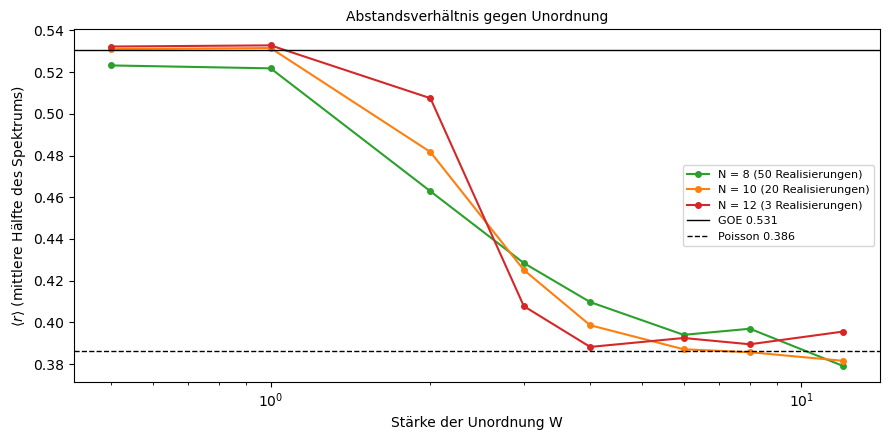

Diagonalisierungen für alle drei Längen: 211 s
W:         0.5    1.0    2.0    3.0    4.0    6.0    8.0   12.0
N =  8:  0.523  0.522  0.463  0.428  0.410  0.394  0.397  0.379
N = 10:  0.531  0.532  0.482  0.425  0.399  0.387  0.386  0.382
N = 12:  0.532  0.533  0.508  0.408  0.388  0.393  0.390  0.396


In [2]:
WS = np.array([0.5, 1, 2, 3, 4, 6, 8, 12])
SAMPLES = {8: 50, 10: 20, 12: 3}
rng = np.random.default_rng(1)
t0 = time.time()
scan = {n: {W: [disorder_sample(n, W, rng) for _ in range(SAMPLES[n])] for W in WS} for n in SAMPLES}
mean_of = lambda n, key: np.array([np.mean([d[key] for d in scan[n][W]]) for W in WS])

fig, ax = plt.subplots(figsize=(9, 4.5))
for n, c in zip(SAMPLES, ["tab:green", "tab:orange", "tab:red"]):
    ax.plot(WS, mean_of(n, "r"), "o-", c=c, ms=4, label=f"N = {n} ({SAMPLES[n]} Realisierungen)")
ax.axhline(R_GOE, color="black", lw=1, label="GOE 0.531")
ax.axhline(R_POISSON, color="black", lw=1, ls="--", label="Poisson 0.386")
ax.set_xscale("log")
ax.set_xlabel("Stärke der Unordnung W")
ax.set_ylabel(r"$\langle r\rangle$ (mittlere Hälfte des Spektrums)")
ax.set_title("Abstandsverhältnis gegen Unordnung", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Diagonalisierungen für alle drei Längen: {time.time() - t0:.0f} s")
print("W:      " + " ".join(f"{W:6.1f}" for W in WS))
for n in SAMPLES:
    print(f"N = {n:2d}: " + " ".join(f"{x:6.3f}" for x in mean_of(n, "r")))

* Das **Bild** zeigt $\langle r\rangle$ gegen $W$ (logarithmisch). Bei $W \le 1$ liegen alle Längen am GOE-Wert, bei $W \ge 6$ am Poisson-Wert; dazwischen fällt $\langle r\rangle$ ab. Die Kurve für $N = 12$ (rot) ist am steilsten: Bei $W = 2$ ist sie am chaotischsten (0.508 gegen 0.463 für $N = 8$), bei $W = 3$ und 4 schon am stärksten lokalisiert (0.408 und 0.388 gegen 0.428 und 0.410).
* Die Kurven kreuzen sich also zwischen $W = 2$ und 3. Das ist das Zeichen eines Übergangs, der mit wachsender Kettenlänge schärfer wird (Theorie, Abschnitt 6). Bei $N = 12$ beruht jeder Punkt nur auf 3 Realisierungen, aber auf jeweils etwa 6000 Abstandsverhältnissen; die Schwankung ist etwa ±0.01.
* Die **Ausgabe** gibt die Tabelle der Werte. Die Werte bei $W = 12$ liegen um 0.38 bis 0.40, leicht neben Poisson, weil bei sehr starker Unordnung fast entartete Niveaus häufiger werden.

##### *2. Eigenzustände: Volumengesetz gegen Flächengesetz*

Sind die Eigenzustände bei starker Unordnung noch so verschränkt wie Zufallszustände, und sehen sie für eine lokale Messung noch thermisch aus? Vorher vorhersagen: Welche Werte nimmt $\langle n\vert Z\vert n\rangle$ in der Mitte an, wenn die Eigenzustände fast Basiszustände sind?

Aus den Diagonalisierungen von Experiment 1 wird für die Eigenzustände nahe der Spektrumsmitte (die 5 % mit der Energie am nächsten an der Mitte, mindestens 20) die Verschränkung der linken Hälfte berechnet und durch den Page-Wert geteilt (**links**). **Rechts** steht die Verteilung von $\langle n\vert Z_\text{Mitte}\vert n\rangle$ für $N = 12$ bei schwacher, mittlerer und starker Unordnung.

**Hintergrund & Fachbegriffe:**
- **Volumengesetz:** Die Verschränkung eines Teilsystems wächst mit seiner Größe; Zufallszustände und chaotische Eigenzustände erreichen fast den Page-Wert.
- **Flächengesetz:** Die Verschränkung hängt nur von der Grenze zwischen den Teilen ab; in einer Kette ist das ein Punkt, die Verschränkung bleibt klein.
- **Page-Wert:** die mittlere Verschränkung der Hälfte eines Zufallszustands, für 12 Qubits 5.28 Bit (Theorie in [Quantenchaos und Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb), Abschnitt 10).

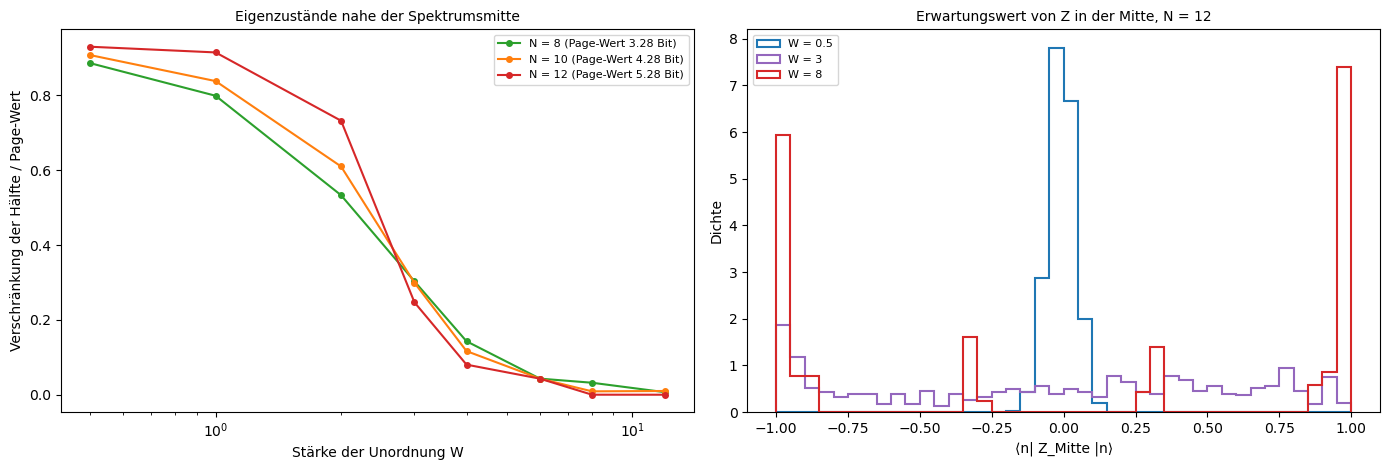

N =  8: S / Page =  0.89  0.80  0.53  0.30  0.14  0.04  0.03  0.01   (S in Bit bei W = 0.5 und 12: 2.91 und 0.023)
N = 10: S / Page =  0.91  0.84  0.61  0.30  0.12  0.04  0.01  0.01   (S in Bit bei W = 0.5 und 12: 3.88 und 0.045)
N = 12: S / Page =  0.93  0.91  0.73  0.25  0.08  0.04  0.00  0.00   (S in Bit bei W = 0.5 und 12: 4.91 und 0.003)
N = 12, W = 0.5: mittleres |⟨Z_Mitte⟩| = 0.04,  Anteil mit |⟨Z⟩| > 0.9: 0%
N = 12, W = 3: mittleres |⟨Z_Mitte⟩| = 0.54,  Anteil mit |⟨Z⟩| > 0.9: 20%
N = 12, W = 8: mittleres |⟨Z_Mitte⟩| = 0.85,  Anteil mit |⟨Z⟩| > 0.9: 75%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for n, c in zip(SAMPLES, ["tab:green", "tab:orange", "tab:red"]):
    axes[0].plot(WS, mean_of(n, "S") / page_entropy(n), "o-", c=c, ms=4, label=f"N = {n} (Page-Wert {page_entropy(n):.2f} Bit)")
axes[0].set_xscale("log")
axes[0].set_xlabel("Stärke der Unordnung W")
axes[0].set_ylabel("Verschränkung der Hälfte / Page-Wert")
axes[0].set_title("Eigenzustände nahe der Spektrumsmitte", fontsize=10)
axes[0].legend(fontsize=8)
for W, c in [(0.5, "tab:blue"), (3, "tab:purple"), (8, "tab:red")]:
    vals = np.concatenate([d["Zc"] for d in scan[12][W]])
    axes[1].hist(vals, bins=np.linspace(-1, 1, 41), density=True, histtype="step", lw=1.5, color=c, label=f"W = {W}")
axes[1].set_xlabel("⟨n| Z_Mitte |n⟩")
axes[1].set_ylabel("Dichte")
axes[1].set_title("Erwartungswert von Z in der Mitte, N = 12", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for n in SAMPLES:
    print(f"N = {n:2d}: S / Page = " + " ".join(f"{x:5.2f}" for x in mean_of(n, "S") / page_entropy(n))
          + f"   (S in Bit bei W = 0.5 und 12: {mean_of(n, 'S')[0]:.2f} und {mean_of(n, 'S')[-1]:.3f})")
for W in (0.5, 3, 8):
    vals = np.abs(np.concatenate([d["Zc"] for d in scan[12][W]]))
    print(f"N = 12, W = {W}: mittleres |⟨Z_Mitte⟩| = {vals.mean():.2f},  Anteil mit |⟨Z⟩| > 0.9: {np.mean(vals > 0.9):.0%}")

* Das **linke Bild** zeigt die Verschränkung in Einheiten des Page-Werts. Bei $W = 0.5$ erreichen die Eigenzustände 89 bis 93 %, mehr für längere Ketten: Volumengesetz wie in der chaotischen Kette. Bei $W \ge 6$ ist sie fast null: Flächengesetz. Wie in Experiment 1 kreuzen sich die Kurven zwischen $W = 2$ und 3: Darunter ist die längere Kette verschränkter, darüber weniger.
* Das **rechte Bild** zeigt die Erwartungswerte von $Z$ in der Mitte. Bei $W = 0.5$ (blau) liegen sie eng um 0, den thermischen Wert bei unendlicher Temperatur, wie die ETH verlangt. Bei $W = 8$ (rot) liegen die meisten nahe $-1$ oder $+1$, mit kleineren Gruppen dazwischen: Jeder Eigenzustand hat sein eigenes, festes $Z$, das l-bit. Bei $W = 3$ (lila) sind die Werte über das ganze Intervall verteilt, der Übergangsbereich.
* Die **Ausgabe** gibt die Verschränkung bei $W = 0.5$ mit 2.91, 3.88 und 4.91 Bit für $N = 8$, 10 und 12, bei $W = 12$ nur noch 0.003 bis 0.045 Bit. Bei $N = 12$ ist das mittlere $\vert\langle Z\rangle\vert$ 0.04, 0.54 und 0.85 für $W = 0.5$, 3 und 8, und der Anteil der Zustände mit $\vert\langle Z\rangle\vert > 0.9$ steigt von 0 % über 20 % auf 75 %.

##### *3. Nach einem Quench: Gedächtnis und langsames Verschränken*

Wie verhält sich die Kette nach einem Quench über sehr lange Zeiten: Vergisst sie das Anfangsmuster, und wie schnell wächst die Verschränkung? Vorher vorhersagen: Wie sieht $S(t)$ auf einer logarithmischen Zeitachse aus, wenn $S \propto \ln t$?

Für $N = 10$ und $W = 0.5$, 2, 4 und 8 startet die Kette in $\vert0011001100\rangle$, je 30 Realisierungen. Über die Eigenzerlegung erhält man den Zustand zu jeder Zeit exakt, hier für 80 Zeiten von 0.01 bis $10^6$ (Theorie, Abschnitte 4 und 5).

**Hintergrund & Fachbegriffe:**
- **Quench:** Start in einem einfachen Zustand, der kein Eigenzustand ist, und freie Zeitentwicklung unter $H$.
- **Gedächtnis $M(t)$:** wie viel vom Anfangsmuster der $z_i$ noch zu sehen ist; 1 am Anfang, 0 nach Thermalisierung bei unendlicher Temperatur.
- **Dephasierung:** l-bits tauschen keine Energie aus, aber sie sammeln relative Phasen und werden dadurch verschränkt.

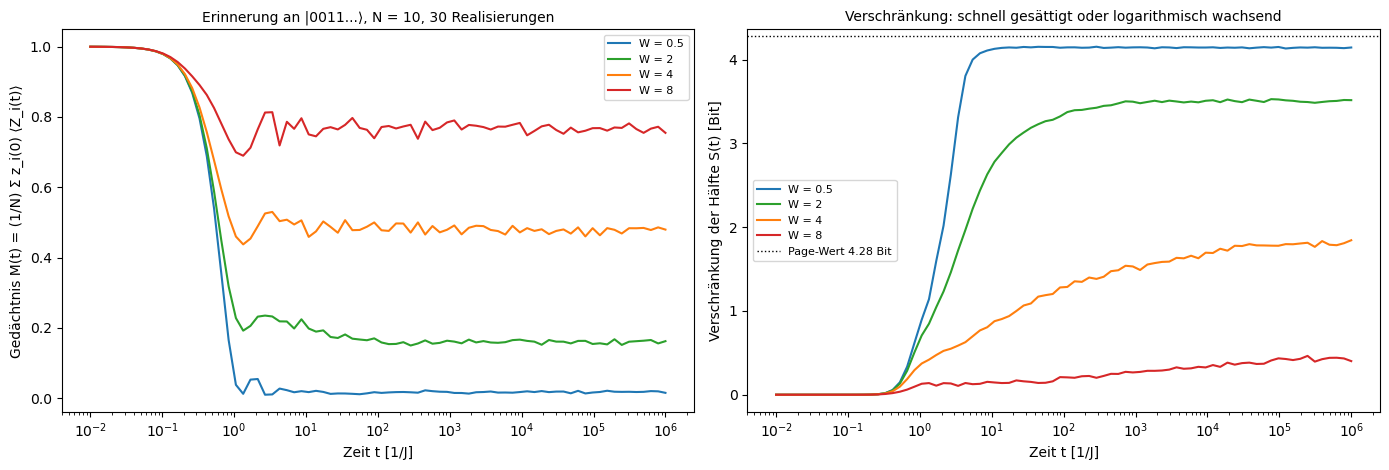

(23 s)
W = 0.5: M(t ≥ 1e5) = 0.019;  S bei t = 1, 10, 1e2, 1e3, 1e4, 1e5, 1e6: 0.90, 4.13, 4.14, 4.15, 4.15, 4.15, 4.15
W = 2: M(t ≥ 1e5) = 0.160;  S bei t = 1, 10, 1e2, 1e3, 1e4, 1e5, 1e6: 0.71, 2.78, 3.32, 3.50, 3.51, 3.53, 3.52
W = 4: M(t ≥ 1e5) = 0.479;  S bei t = 1, 10, 1e2, 1e3, 1e4, 1e5, 1e6: 0.37, 0.88, 1.28, 1.53, 1.70, 1.78, 1.84
W = 8: M(t ≥ 1e5) = 0.767;  S bei t = 1, 10, 1e2, 1e3, 1e4, 1e5, 1e6: 0.13, 0.15, 0.21, 0.27, 0.33, 0.43, 0.40
W = 4: Zuwachs von S pro Zehnerpotenz der Zeit zwischen t = 10 und 1e5: 0.224 Bit
W = 8: Zuwachs von S pro Zehnerpotenz der Zeit zwischen t = 10 und 1e5: 0.072 Bit


In [4]:
N3, REAL3 = 10, 30
times = np.geomspace(0.01, 1e6, 80)
rng = np.random.default_rng(2)
t0 = time.time()
dyn = {}
for W in [0.5, 2, 4, 8]:
    runs = [quench(N3, W, rng, times) for _ in range(REAL3)]
    dyn[W] = (np.mean([m for m, _ in runs], axis=0), np.mean([s for _, s in runs], axis=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for W, c in zip(dyn, ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    axes[0].semilogx(times, dyn[W][0], c=c, label=f"W = {W}")
    axes[1].semilogx(times, dyn[W][1], c=c, label=f"W = {W}")
axes[1].axhline(page_entropy(N3), color="black", ls=":", lw=1, label=f"Page-Wert {page_entropy(N3):.2f} Bit")
axes[0].set_xlabel("Zeit t [1/J]")
axes[0].set_ylabel("Gedächtnis M(t) = (1/N) Σ z_i(0) ⟨Z_i(t)⟩")
axes[0].set_title(f"Erinnerung an |0011...⟩, N = {N3}, {REAL3} Realisierungen", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Zeit t [1/J]")
axes[1].set_ylabel("Verschränkung der Hälfte S(t) [Bit]")
axes[1].set_title("Verschränkung: schnell gesättigt oder logarithmisch wachsend", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"({time.time() - t0:.0f} s)")
pick = lambda y, t: y[np.argmin(np.abs(times - t))]
for W in dyn:
    M, S = dyn[W]
    print(f"W = {W}: M(t ≥ 1e5) = {M[times >= 1e5].mean():.3f};  S bei t = 1, 10, 1e2, 1e3, 1e4, 1e5, 1e6: "
          + ", ".join(f"{pick(S, t):.2f}" for t in [1, 10, 1e2, 1e3, 1e4, 1e5, 1e6]))
for W in (4, 8):
    window = (times > 10) & (times < 1e5)
    slope = np.polyfit(np.log10(times[window]), dyn[W][1][window], 1)[0]
    print(f"W = {W}: Zuwachs von S pro Zehnerpotenz der Zeit zwischen t = 10 und 1e5: {slope:.3f} Bit")

* Das **linke Bild** zeigt das Gedächtnis. Bis $t \approx 0.3$ bleibt es bei 1, dann fällt es. Bei $W = 0.5$ (blau) fällt es fast auf null (0.019): Die Kette thermalisiert. Bei stärkerer Unordnung bleibt es stehen, bei 0.16 ($W = 2$), 0.48 ($W = 4$) und 0.77 ($W = 8$), und ändert sich zwischen $t = 10$ und $10^6$ nicht mehr: Die Kette erinnert sich für immer.
* Das **rechte Bild** zeigt die Verschränkung. Bei $W = 0.5$ steigt sie bis $t \approx 5$ steil an und bleibt dann bei 4.15 Bit, knapp unter dem Page-Wert 4.28. Bei $W = 4$ (orange) dagegen steigt sie nach einem schnellen Anfang über fünf Zehnerpotenzen der Zeit gleichmäßig weiter, als Gerade auf der logarithmischen Achse: das logarithmische Wachstum der Vielteilchenlokalisierung. Bei $W = 8$ geschieht dasselbe langsamer.
* Die **Ausgabe** gibt $S$ bei $W = 4$: 0.88 Bit bei $t = 10$, 1.28 bei $10^2$, 1.53 bei $10^3$, 1.70 bei $10^4$, 1.78 bei $10^5$; die Anpassung zwischen $t = 10$ und $10^5$ gibt 0.224 Bit pro Zehnerpotenz, bei $W = 8$ 0.072. Die kleinere Steigung bei stärkerer Unordnung passt zu $S \propto \xi\ln t$ mit kürzerer Lokalisierungslänge $\xi$. Bei 10 Qubits flacht das Wachstum gegen Ende ab, weil die Kette endlich ist.

##### *4. Das Langzeit-Gedächtnis gegen die Unordnung*

Wie viel Gedächtnis bleibt für unendlich lange Zeiten, und hängt das von der Kettenlänge ab? Vorher vorhersagen: Was sollte mit $M_\infty$ bei schwacher Unordnung passieren, wenn die Kette länger wird?

Aus den Diagonalisierungen von Experiment 1 wird für den Anfangszustand $\vert0011\dots\rangle$ das diagonale Ensemble $M_\infty = \sum_n\vert c_n\vert^2\frac1N\sum_iz_i(0)\langle n\vert Z_i\vert n\rangle$ berechnet (Theorie, Abschnitt 4), für alle $W$ und $N = 8$, 10, 12.

**Hintergrund & Fachbegriffe:**
- **Diagonales Ensemble:** der Langzeitmittelwert, berechnet aus den Gewichten $\vert c_n\vert^2$ des Anfangszustands und den Erwartungswerten in den Eigenzuständen (siehe [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb), Abschnitt 1).
- **Ordnungsparameter:** eine Größe, die in einer Phase null und in der anderen endlich ist; $M_\infty$ spielt diese Rolle für den MBL-Übergang.

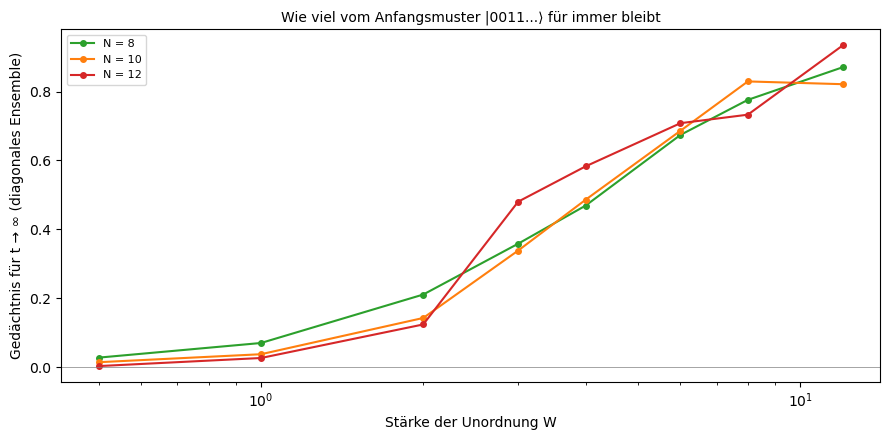

N =  8: M_∞ =  0.028  0.071  0.211  0.359  0.469  0.674  0.776  0.871
N = 10: M_∞ =  0.015  0.038  0.143  0.339  0.486  0.686  0.829  0.821
N = 12: M_∞ =  0.004  0.027  0.124  0.481  0.583  0.708  0.733  0.934


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for n, c in zip(SAMPLES, ["tab:green", "tab:orange", "tab:red"]):
    ax.plot(WS, mean_of(n, "memory"), "o-", c=c, ms=4, label=f"N = {n}")
ax.axhline(0, color="grey", lw=0.5)
ax.set_xscale("log")
ax.set_xlabel("Stärke der Unordnung W")
ax.set_ylabel("Gedächtnis für t → ∞ (diagonales Ensemble)")
ax.set_title("Wie viel vom Anfangsmuster |0011...⟩ für immer bleibt", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for n in SAMPLES:
    print(f"N = {n:2d}: M_∞ = " + " ".join(f"{x:6.3f}" for x in mean_of(n, "memory")))

* Das **Bild** zeigt $M_\infty$ gegen $W$. Bei schwacher Unordnung ist es klein und wird mit wachsendem $N$ noch kleiner (bei $W = 0.5$: 0.028, 0.015, 0.004): Im Grenzfall langer Ketten verschwindet das Gedächtnis, die Kette thermalisiert. Bei starker Unordnung ist es groß, 0.7 bis 0.9, und hängt kaum von $N$ ab.
* Zwischen $W = 2$ und 3 kreuzen sich die Kurven wieder: Bei $W = 2$ hat die längste Kette das kleinste Gedächtnis (0.124 gegen 0.211), bei $W = 3$ das größte (0.481 gegen 0.359). Alle drei Diagnosen, Spektrum, Verschränkung und Gedächtnis, zeigen denselben Übergangsbereich.
* Die **Ausgabe** gibt die Werte. Dass bei $W = 8$ die Kette mit 12 Qubits unter der mit 10 liegt (0.733 gegen 0.829), ist die Schwankung durch nur 3 Realisierungen: Das Gedächtnis hängt stark davon ab, wie die Felder genau verteilt sind.

#### **Ergebnis**

Beim Lauf vom 2026-10-24 (Ising-Kette mit $J = h_x = 1$ und Längsfeldern $h_i = 0.5 + W u_i$):

- **Spektrum (Experiment 1):** $\langle r\rangle$ fällt von 0.53 (GOE) bei $W \le 1$ auf 0.38 bis 0.40 (Poisson) bei $W \ge 6$. Die Kurven für $N = 8$, 10 und 12 kreuzen sich zwischen $W = 2$ und 3; die längste Kette ist bei $W = 2$ am chaotischsten (0.508) und bei $W = 3$ am stärksten lokalisiert (0.408).
- **Eigenzustände (Experiment 2):** Die Verschränkung der Eigenzustände nahe der Spektrumsmitte fällt von 89 bis 93 % des Page-Werts (Volumengesetz) auf fast null (Flächengesetz), mit demselben Kreuzungsbereich. Bei $N = 12$ und $W = 8$ haben 75 % der Eigenzustände $\vert\langle Z_\text{Mitte}\rangle\vert > 0.9$, bei $W = 0.5$ keiner.
- **Quench (Experiment 3):** Nach dem Start in $\vert0011\dots\rangle$ ($N = 10$) fällt das Gedächtnis bei $W = 0.5$ auf 0.02, bei $W = 2$, 4 und 8 bleibt es bei 0.16, 0.48 und 0.77 bis $t = 10^6$. Die Verschränkung sättigt bei $W = 0.5$ nach $t \approx 5$ bei 4.15 Bit; bei $W = 4$ wächst sie von $t = 10$ bis $10^5$ logarithmisch, um 0.22 Bit pro Zehnerpotenz (bei $W = 8$ um 0.07).
- **Langzeit-Gedächtnis (Experiment 4):** $M_\infty$ ist bei schwacher Unordnung klein und nimmt mit $N$ ab (0.028, 0.015, 0.004 bei $W = 0.5$), bei starker Unordnung 0.7 bis 0.9; die Kurven kreuzen sich wieder zwischen $W = 2$ und 3.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Übergangsbereich:** In Experiment 3 zusätzlich $W = 3$. *(Vorhersage: Die Verschränkung wächst zuerst langsam, 1.75 Bit bei $t = 10$ und 2.42 bei $10^2$, sättigt aber schon um $t \approx 10^3$ bei etwa 2.7 Bit; das Gedächtnis bleibt bei etwa 0.31. Bei 10 Qubits ist der Übergangsbereich weder klar chaotisch noch klar lokalisiert.)*
2. **Ein Anfangszustand mit tiefer Energie:** In `start_state` den Néel-Zustand `int(("01" * n)[:n], 2)` nehmen. *(Vorhersage: Wegen der antiferromagnetischen Kopplung $J > 0$ liegt seine Energie tief im Spektrum, bei etwa 14 % der Breite über dem Grundzustand. Bei $W = 0.5$ bleibt deshalb etwas mehr Gedächtnis, etwa 0.08 statt 0.02 bei $N = 10$; bei $W = 4$ etwa 0.5 wie beim Muster $\vert0011\dots\rangle$.)*
3. **Mehr Realisierungen:** `SAMPLES = {8: 50, 10: 20, 12: 10}` (etwa 7 Minuten). *(Vorhersage: Die Kurven für $N = 12$ werden glatter, der Kreuzungsbereich zwischen $W = 2$ und 3 bleibt, und die unregelmäßige Reihenfolge von $M_\infty$ bei $W = 8$ aus Experiment 4 verschwindet oder wird kleiner.)*
4. **Eine längere Kette im Quench:** `N3 = 12` mit `REAL3 = 10` (einige Minuten). *(Vorhersage: Bei $W = 4$ wächst die Verschränkung länger logarithmisch, bevor die endliche Kette sie begrenzt; bei $W = 0.5$ sättigt sie bei etwa 5.1 Bit, nahe am Page-Wert 5.28.)*
5. **Ohne mittleres Feld:** $h_z = 0$, also $h_i = W u_i$. *(Vorhersage: Bei starker Unordnung kaum ein Unterschied; bei schwacher Unordnung kommt die Kette dem integrablen Punkt $h_z = 0$ nahe, und bei sehr kleinem $W$ fällt $\langle r\rangle$ unter den GOE-Wert.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist Anderson-Lokalisierung, und was ist bei Vielteilchenlokalisierung anders?</summary>

Ein einzelnes Teilchen in einem ungeordneten Potential hat exponentiell lokalisierte Eigenzustände, weil sich seine Ausbreitungswege durch Interferenz auslöschen. Bei Vielteilchenlokalisierung wechselwirken die Teilchen und könnten Energie austauschen; trotzdem bleibt das System bei starker Unordnung lokalisiert und thermalisiert nie.
</details>

<details><summary>2. Was sind l-bits, und warum erklären sie alle Eigenschaften der MBL-Phase?</summary>

Quasilokale Erhaltungsgrößen $\tau_i^z = UZ_iU^\dagger$, eine pro Platz. $H$ ist in ihnen diagonal, mit Kopplungen, die exponentiell mit dem Abstand abfallen. Jeder Eigenzustand ist durch die Werte der l-bits festgelegt: Poisson-Spektrum, Flächengesetz, Gedächtnis und logarithmische Verschränkung folgen daraus.
</details>

<details><summary>3. Warum ist das Spektrum eines lokalisierten Systems Poisson-verteilt?</summary>

Die Energien hängen von $N$ unabhängigen Quantenzahlen ab, den Werten der l-bits. Niveaus mit verschiedenen Quantenzahlen stoßen sich nicht ab, wie in einem integrablen System. In Experiment 1 fällt $\langle r\rangle$ von 0.53 auf etwa 0.39.
</details>

<details><summary>4. Was unterscheidet Volumen- und Flächengesetz der Verschränkung?</summary>

Volumengesetz: Die Verschränkung wächst mit der Größe des Teilsystems, chaotische Eigenzustände erreichen fast den Page-Wert (93 % bei 12 Qubits und $W = 0.5$). Flächengesetz: Sie hängt nur von der Grenze ab und bleibt in einer Kette klein; MBL-Eigenzustände sind fast Produktzustände der l-bits.
</details>

<details><summary>5. Woran sieht man im Experiment, dass ein System nicht thermalisiert?</summary>

Am Gedächtnis an das Anfangsmuster: $M(t) = \frac1N\sum z_i(0)\langle Z_i(t)\rangle$ bleibt endlich, statt auf den thermischen Wert null zu fallen. Kalte Atome (Schreiber et al. 2015) messen dafür die Imbalance zwischen geraden und ungeraden Plätzen.
</details>

<details><summary>6. Warum wächst die Verschränkung in der MBL-Phase logarithmisch?</summary>

L-bits im Abstand $r$ sind über $\tilde J \sim e^{-r/\xi}$ gekoppelt und werden erst nach der Zeit $t \sim e^{r/\xi}$ durch Dephasierung verschränkt. Bis zur Zeit $t$ reicht die Verschränkung also über den Abstand $\xi\ln t$: $S \propto \xi\ln t$. Gemessen: 0.22 Bit pro Zehnerpotenz bei $W = 4$.
</details>

<details><summary>7. Was unterscheidet das Wachstum der Verschränkung bei MBL von dem bei Anderson-Lokalisierung?</summary>

Ohne Wechselwirkung sind die l-bits nicht gekoppelt, und die Verschränkung bleibt nach einem kurzen Anstieg stehen. Das langsame Weiterwachsen ist die Spur der Wechselwirkung, die bei MBL nur Phasen, aber keine Energie transportiert.
</details>

<details><summary>8. Warum wird das Langzeit-Gedächtnis bei schwacher Unordnung mit wachsender Kette kleiner?</summary>

Die Kette thermalisiert, und der thermische Wert von $M$ bei unendlicher Temperatur ist null. Was in endlichen Ketten bleibt, sind Korrekturen, die mit der Größe verschwinden: 0.028, 0.015, 0.004 für $N = 8$, 10, 12 bei $W = 0.5$.
</details>

<details><summary>9. Wie schätzt man den Übergang aus Rechnungen an kleinen Ketten?</summary>

Man trägt eine Größe für mehrere Längen gegen $W$ auf und sucht den Punkt, an dem sich die Kurven kreuzen: darunter wird die längere Kette chaotischer, darüber lokalisierter. Hier liegt er für alle drei Größen zwischen $W = 2$ und 3.
</details>

<details><summary>10. Warum ist umstritten, ob es MBL in unendlich langen Ketten gibt?</summary>

Der Kreuzungspunkt wandert mit wachsender Länge zu stärkerer Unordnung, und seltene, zufällig schwach ungeordnete Bereiche könnten als Wärmebad die Lokalisierung von innen zerstören (Lawinen). Sicher ist, dass bei starker Unordnung die Zeiten dafür so lang sind, dass sich das System praktisch lokalisiert verhält.
</details>

<details><summary>11. Warum startet der Quench in |0011…⟩ und nicht im Néel-Zustand |0101…⟩?</summary>

Bei antiferromagnetischer Kopplung hat der Néel-Zustand eine tiefe Energie, nahe am Grundzustand. Dort ist der thermische Wert des Gedächtnisses nicht null, und man könnte ein endliches $M$ mit Lokalisierung verwechseln. $\vert0011\dots\rangle$ liegt nahe der Spektrumsmitte, bei unendlicher Temperatur.
</details>

<details><summary>12. Wie hängt Vielteilchenlokalisierung mit den anderen Notebooks der Serie zusammen?</summary>

Sie verletzt alles, was dort für chaotische Systeme gilt: Das Spektrum ist Poisson statt GOE, die Eigenzustände erfüllen die ETH nicht und sind nicht wie Zufallszustände verschränkt, und Information breitet sich nur logarithmisch statt ballistisch aus.
</details>

#### **Nächste Schritte**

- **Anderson gegen MBL direkt:** eine XX-Kette mit zufälligen Feldern (freie Fermionen) gegen eine XXZ-Kette mit derselben Unordnung; nur mit der Wechselwirkung $\Delta\sum Z_iZ_{i+1}$ wächst die Verschränkung logarithmisch (Bardarson, Pollmann und Moore 2012).
- **Logarithmischer Lichtkegel:** die OTOCs aus [Quantenchaos und Scrambling](https://github.com/deltorobarba/science/blob/main/quantum/chaos_scrambling.ipynb), Experiment 1, mit Unordnung: Die Front breitet sich nur wie $\ln t$ aus.
- **L-bits konstruieren:** den Operator $\tau_i^z$ als Langzeitmittel von $Z_i$ in der Eigenbasis berechnen und seine Ausdehnung um Platz $i$ messen.
- **Größere Ketten:** Mit Shift-Invert-Verfahren berechnet man nur einige Dutzend Eigenzustände in der Spektrumsmitte und kommt bis etwa 20 Qubits; damit lässt sich die Drift des Kreuzungspunkts verfolgen.
- **Experimente:** Imbalance-Messungen mit kalten Atomen und Ionen; Zeitkristalle, bei denen Lokalisierung ein angetriebenes System vor dem Aufheizen schützt.

#### **Referenzen**

- Anderson, P. W. (1958): *Absence of diffusion in certain random lattices*, Phys. Rev. 109, 1492.
- Gornyi, I. V., Mirlin, A. D. & Polyakov, D. G. (2005): *Interacting electrons in disordered wires: Anderson localization and low-T transport*, Phys. Rev. Lett. 95, 206603.
- Basko, D. M., Aleiner, I. L. & Altshuler, B. L. (2006): *Metal–insulator transition in a weakly interacting many-electron system with localized single-particle states*, Ann. Phys. 321, 1126.
- Oganesyan, V. & Huse, D. A. (2007): *Localization of interacting fermions at high temperature*, Phys. Rev. B 75, 155111.
- Žnidarič, M., Prosen, T. & Prelovšek, P. (2008): *Many-body localization in the Heisenberg XXZ magnet in a random field*, Phys. Rev. B 77, 064426.
- Pal, A. & Huse, D. A. (2010): *Many-body localization phase transition*, Phys. Rev. B 82, 174411.
- Bardarson, J. H., Pollmann, F. & Moore, J. E. (2012): *Unbounded growth of entanglement in models of many-body localization*, Phys. Rev. Lett. 109, 017202.
- Serbyn, M., Papić, Z. & Abanin, D. A. (2013): *Local conservation laws and the structure of the many-body localized states*, Phys. Rev. Lett. 111, 127201.
- Huse, D. A., Nandkishore, R. & Oganesyan, V. (2014): *Phenomenology of fully many-body-localized systems*, Phys. Rev. B 90, 174202.
- Luitz, D. J., Laflorencie, N. & Alet, F. (2015): *Many-body localization edge in the random-field Heisenberg chain*, Phys. Rev. B 91, 081103.
- Schreiber, M. et al. (2015): *Observation of many-body localization of interacting fermions in a quasirandom optical lattice*, Science 349, 842.
- Imbrie, J. Z. (2016): *On many-body localization for quantum spin chains*, J. Stat. Phys. 163, 998.
- Smith, J. et al. (2016): *Many-body localization in a quantum simulator with programmable random disorder*, Nat. Phys. 12, 907.
- De Roeck, W. & Huveneers, F. (2017): *Stability and instability towards delocalization in many-body localization systems*, Phys. Rev. B 95, 155129.
- Abanin, D. A., Altman, E., Bloch, I. & Serbyn, M. (2019): *Colloquium: Many-body localization, thermalization, and entanglement*, Rev. Mod. Phys. 91, 021001.
- Šuntajs, J., Bonča, J., Prosen, T. & Vidmar, L. (2020): *Quantum chaos challenges many-body localization*, Phys. Rev. E 102, 062144.